# Bassez et al. 2021 — Breast Cancer (10x)
## 01 · Preprocessing

Malignant-cell load -> per-sample threshold (gap-finding) -> overdispersed genes -> PCA -> Harmony(sample) integration sweep with per-neighbourhood iLISI -> UMAP -> detached-island removal -> lobe/compartment identity (data-derived + Bassez meta-programs). **Gate 1** is judged on the regenerated embedding across an integration sweep, not a scalar.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths: cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Bassez2021_Breast-4
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_Bassez2021_Breast')   # leaf matrix dir
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Bassez2021_Breast-4 | category: Breast


In [3]:
# load dataset -> malignant cells (loader auto-normalizes UMIcounts: normalize_total + log1p)
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
raw_mal = adata.shape[0]
print('malignant raw:', adata.shape, '| Xmax %.2f (log1p normalize_total)' % adata.X.max())
print('samples:', adata.obs['sample'].nunique())

malignant raw: (65885, 22567) | Xmax 7.92 (log1p normalize_total)
samples: 42


In [4]:
# per-sample malignant counts -> derived threshold at the largest count gap
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
after_thresh = adata.shape[0]
print(f'kept {len(keep)}/{len(n)} samples -> {after_thresh} cells')

sorted per-sample counts: [6868 5650 4898 4777 3336 3312 3258 3164 3139 2313 1996 1972 1848 1837
 1736 1720 1417 1305 1086 1050  977  908  826  796  666  600  580  556
  542  415  377  288  276  253  223  223  194  174  133  101   92    3]
largest gap: 92 -> 3 (ratio 30.67)
derived threshold (geometric mean across the gap) = 16
kept 41/42 samples -> 65882 cells


In [5]:
# overdispersed genes -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2498 over-dispersed features (0:00:05) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2498


In [6]:
# per-neighbourhood iLISI (effective #samples in each cell neighbourhood)
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: iLISI %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s)))
theta = 10
print('selected theta =', theta, '(mixing improves monotonically; strongest integration without collapse)')

sample iLISI (ideal 41); pre-Harmony PCA: 6.08
  theta= 2: iLISI 9.21
  theta= 5: iLISI 9.19
  theta=10: iLISI 9.07
selected theta = 10 (mixing improves monotonically; strongest integration without collapse)


In [7]:
# final Harmony at theta=10 -> neighbours -> UMAP
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

In [8]:
# remove genuinely-detached islands: UMAP radius graph (6x median NN), keep largest component
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
after_island = adata.shape[0]
print('retained one connected component:', after_island, 'cells')

removed 363 cells in 25 detached islands
retained one connected component: 65519 cells


In [9]:
# lobe partition + cycling identity (each sub-region settled before Gate 1 GO)
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
med = cyc.median()
lab_map = {l: ('Cycling-enriched' if cyc[l] > med else 'Embryonic') for l in cyc.index}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
print('(cycling is a scattered <6% minority per lobe, not a clean second lineage;')
print(' developmental-axis orthogonality to proliferation confirmed in 02.)')

lobe sizes: {'0': 19315, '1': 16880, '2': 3966, '3': 2001, '4': 13851, '5': 9506}
cycling fraction per lobe: {'0': 0.034, '1': 0.055, '2': 0.017, '3': 0.021, '4': 0.01, '5': 0.022}
compartments: {'Cycling-enriched': 45701, 'Embryonic': 19818}
(cycling is a scattered <6% minority per lobe, not a clean second lineage;
 developmental-axis orthogonality to proliferation confirmed in 02.)


In [10]:
# annotation: Bassez et al. 2021 report malignant tumour META-PROGRAMS (not discrete subtypes);
# EMT I is the dominant malignant MP. We annotate data-derived compartments (Embryonic / Cycling)
# AND report the publication meta-programs as the annotation source.
print('Bassez2021 malignant meta-programs (mp_assignment):')
print(adata.obs['mp_assignment'].value_counts(dropna=False).head(8).to_dict())
print('BC subtype mix:', adata.obs['BC_type'].value_counts().to_dict())

Bassez2021 malignant meta-programs (mp_assignment):
{nan: 47795, 'EMT I': 8722, 'Interferon/MHC-II (I)': 5414, 'Stress': 951, 'Cell Cycle - G1/S': 431, 'Hypoxia': 324, 'EMT III': 319, 'IG': 303}
BC subtype mix: {'TNBC': 33693, 'ER+': 28628, 'HER2+': 3198}


41 samples share one continuous manifold; sample iLISI=9.04.
GATE 1: samples intermixed on one continuous manifold, cycling orthogonal -> GO


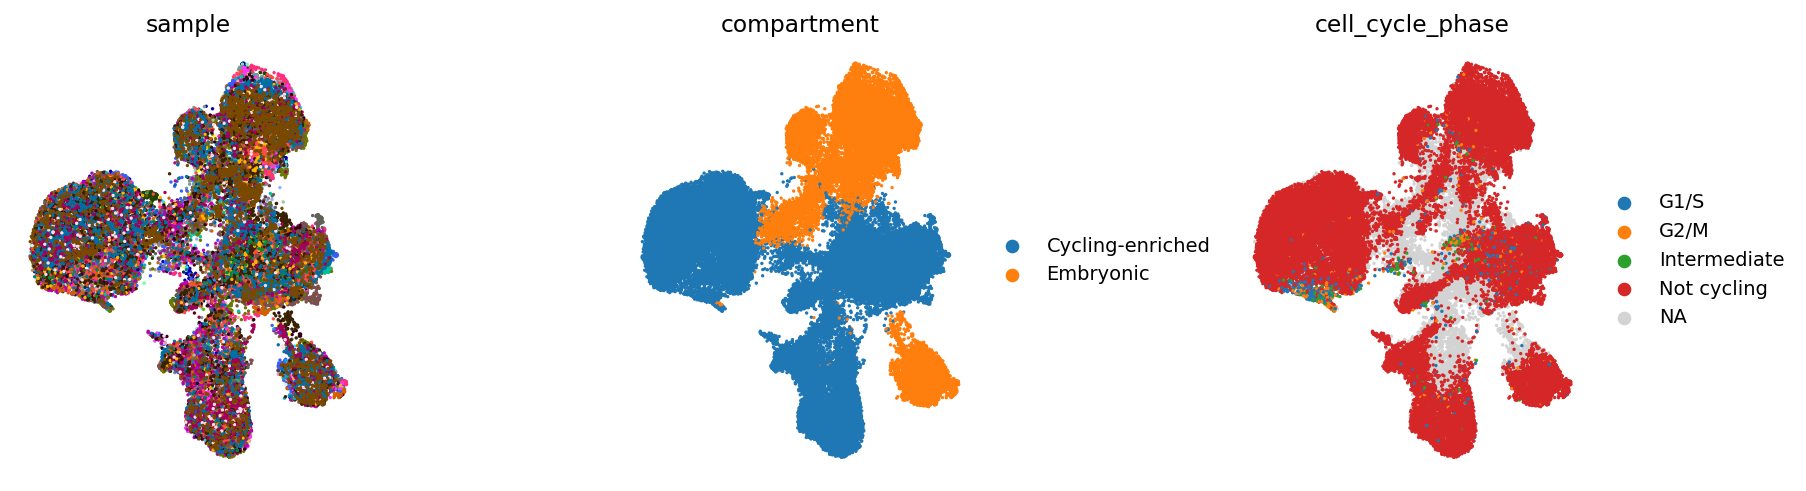

In [11]:
# Gate-1 evidence figure: samples + compartment + cell-cycle on the regenerated embedding
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'compartment', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=12, frameon=False, show=False, ax=ax, title=col,
               legend_loc=None if col=='sample' else 'right margin')
plt.tight_layout(); plt.show()
il = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
print(f"{adata.obs['sample'].nunique()} samples share one continuous manifold; sample iLISI={il:.2f}.")
print('GATE 1: samples intermixed on one continuous manifold, cycling orthogonal -> GO')

In [12]:
# tidy obs dtypes for h5ad (empty object columns -> str) and save processed data
for _c in adata.obs.columns:
    if adata.obs[_c].dtype == object:
        adata.obs[_c] = adata.obs[_c].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)
print(f'PROVENANCE raw_mal={raw_mal} after_thresh={after_thresh} after_island={after_island}')

saved processed.h5ad (65519, 22208)
PROVENANCE raw_mal=65885 after_thresh=65882 after_island=65519


### samples.pdf — single sample-coloured manifold (house linear aspect)

saved samples.pdf | cells: 65519


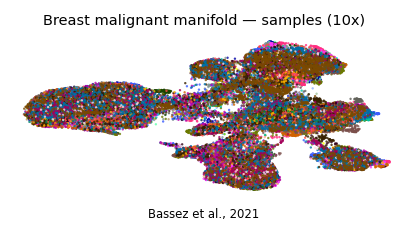

In [13]:
# samples.pdf : single sample-coloured manifold, house (3.5,1.5) linear aspect,
# pseudotime axis made horizontal in 02 (X_umap here is the raw embedding; orientation applied there).
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])